# 08-I2C与SPI通信

> 从“能发出一个字节”走到“能完整读写一个外设”：接线、时序、事务边界、超时和设备驱动必须一起理解。

这是「嵌入式单片机一套通关」十二篇笔记的第 08 篇，承接第 04 篇的 GPIO、第 05 篇的计时与中断、第 06 篇的 DMA。本篇围绕 **I2C 原理与软硬件实现 → 外置时钟与屏幕 → SPI 原理与传输 → 总线和设备驱动分层 → 排错与练习** 展开。

学完应能回答：为什么 I2C 要上拉？0x3C 和 0x78 是不是同一个地址？谁发 ACK？读最后一个字节为什么要 NACK？为什么硬件 I2C 读 1、2、3 个字节的结束流程不同？SPI 模式由什么决定？DMA 完成后为什么不能立刻拉高 CS？


## 1. 本篇范围与阅读方式

| 课程材料 | 本篇整理内容 |
|---|---|
| I2C 原理、软实现、硬实现、GD32F4 查询 | 开漏电气连接、地址、ACK、寄存器读写、GPIO 模拟、硬件事件 |
| I2C 时钟案例 | PCF8563 外置 RTC 的驱动迁移和时间读取思路 |
| I2C 屏幕案例 | OLED 总线接口、命令与数据、缓冲与刷新 |
| SPI 原理、GD32F4 查询、屏幕案例 | 信号方向、四种模式、时钟、全双工、片选与屏幕控制 |
| 官方手册补充 | I2C 接收尾部、状态清除、SPI 传输结束、软件 NSS 与 DMA 边界 |

资料来自[用户提供的知识库](https://www.yuque.com/embheima/mcu)，现跳转至[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。已阅读本篇相关 **9 个页面的可访问正文与可见短代码**，并核对 GD32F4xx User Manual 3.4 的相关完整页。部分长代码编辑器未展开，完整工程和附件未下载。

示例沿用 **GD32F407VET6、匹配的 GD32F4xx SPL/CMSIS、C99**。课程部分屏幕资料混用了 STM32F407 与 GD32F470；理解原理后仍需核对本机型号、复用表和库接口，不能只换头文件就认为移植成功。

正文中的 `app_*`、`bb_*`、`board_*` 是本篇说明的应用接口约定，**不是厂商库现成函数**。标明“流程”或“片段”的内容需要补齐工程、错误清理和板级实现。三张图片为自绘学习示意。

本篇没有进行 SDK 编译、烧录、上板运行或电气测量。电脑上的算法与计算复核不能代替实际波形验收。建议先读第 2～16 节学习 I2C，再读第 17～25 节学习 SPI，最后用第 26～31 节做整合与复习。


## 2. I2C 与 SPI：先分清各自怎样选择设备

两者都是常见的板内同步通信方式，由主机提供时钟，但设备选择和数据反馈方式不同。

| 项目 | I2C | 普通四线 SPI |
|---|---|---|
| 基本信号 | SCL、SDA | SCK、MOSI、MISO、CS/NSS |
| 多设备选择 | 地址 | 每个从设备一个片选，通常低有效 |
| 数据方向 | SDA 交替发送与接收，半双工 | MOSI 与 MISO 可以同时传输，全双工 |
| 电气方式 | 常用开漏，需要上拉 | 常用推挽；未选设备 MISO 应释放为高阻 |
| 协议反馈 | 每个字节后有 ACK/NACK | 没有统一的 ACK；由设备协议判断成功 |
| 时序关键 | START、STOP、重复起始、时钟拉伸 | CPOL、CPHA、CS 建立/保持、多字节边界 |
| 常见用途 | RTC、低速传感器、配置寄存器、小屏幕 | Flash、较高速传感器、显示屏、ADC |

I2C 常见于需要节省引脚、多个低速外设共线的场景。SPI 常见于较大连续数据量、较高时钟和明确片选的场景。选择还要看外设实际支持什么、线路长度、功耗和 CPU 占用。

**速度不能只看波特率数字。** I2C 的地址和 ACK 占时间；SPI 往往有命令、寄存器地址、dummy 和片选间隔。屏幕刷新速度还受软件绘图、缓冲复制和总线占用影响。

同步总线仍需要双方约定。主机有时钟并不代表任意频率、任意模式都能通信。I2C 400 kHz 和 SPI 10 MHz 都必须在器件、电气及本机配置允许范围内使用。


## 3. I2C 接线：开漏“写 1”表示释放线路

常见 I2C 接法是所有设备的 SCL 相连、SDA 相连，共地，并分别用电阻上拉到兼容的逻辑电源。

```text
3.3 V ── Rp_SCL ──┐
MCU SCL ──────────┴────────── 外设 SCL

3.3 V ── Rp_SDA ──┐
MCU SDA ──────────┴────────── 外设 SDA

MCU GND ──────────────────── 外设 GND
```

上图只强调连接关系：**两个上拉分别连接 SCL 和 SDA**，不能将两根信号短接。3.3 V 只是兼容电压示例；检查实物时以原理图和引脚定义为准。

| 开漏输出动作 | 管脚实际行为 | 线路可能读到的电平 |
|---|---|---|
| 写 0 | 本设备拉低 | 低 |
| 写 1 | 本设备释放，不主动驱动高 | 若所有设备释放，由上拉变高；若有人拉低，仍为低 |

因此，`SDA=1` 不能被理解成“强制输出高”。发送 1、等待 ACK、读取数据时，都要让线路能被其他设备拉低。对开漏输出，可以释放 SDA 后读取输入状态，不一定每一位都切 GPIO 输入/输出模式。

上拉过大，线电容充电慢，上升沿可能不合格；过小，拉低时电流增大，设备可能无法满足低电平指标。内部弱上拉通常不适合作为高速总线的唯一上拉。

学习用估算：`tr ≈ 0.8473 × Rp × Cbus`。若 `Cbus=100 pF`，`Rp=10 kΩ`，上升时间约 **847 ns**；换成 `4.7 kΩ` 约 **398 ns**。这解释了为何课程图中的 10 kΩ 不能被当成任何线路、任何速度都通用的值。常规快速模式的 300 ns 上升时间要求下，此负载的估算 `Rp_max≈3.54 kΩ`；最低阻值还受供电、允许低电平和器件灌电流限制。

这些是 RC 模型下的选型提示，未作实测。总线电容包括走线、连接器、输入管脚和探头；多个模块自带上拉时，电阻会并联。**先查每个模块的上拉、电压和电平兼容性，再连接。**


## 4. I2C 时序：START、数据、ACK 和 STOP

I2C 总线空闲时 SCL、SDA 都应为高。普通数据位在 SCL 高期间保持稳定，在 SCL 低期间改变。

| 信号 / 阶段 | 判断方式 | 谁控制 |
|---|---|---|
| START | SCL 高时，SDA 从高变低 | 主机发起 |
| STOP | SCL 高时，SDA 从低变高 | 主机结束 |
| 数据位 | SCL 高期间 SDA 稳定 | 当前发送方控制 SDA |
| ACK | 第 9 个时钟期间 SDA 为低 | 当前接收方拉低 SDA |
| NACK | 第 9 个时钟期间 SDA 为高 | 当前接收方释放 SDA |
| 时钟拉伸 | 主机释放 SCL 后，线路暂时仍为低 | 支持该功能的设备拉低 SCL |

一个地址字节或数据字节一般需要 **8 个数据时钟 + 1 个应答时钟**，高位先传。主机仍负责产生第 9 个时钟；ACK 方接管的是 **SDA**。不能把“等待从机 ACK”写成“把 SCL 的时钟控制权交给从机”。

读传输时，外设发数据，主机成为接收方，因此主机给前面的字节 ACK，给最后一字节 NACK，再结束事务。最后这个 NACK 是正常协议动作，和地址无人应答的 NACK 不是同一个错误场景。

时钟拉伸还说明：软件释放 SCL 后，应检查**实际 SCL 输入**再开始计算高电平保持时间。只写高后立即读取 SDA，可能在真正的时钟边沿到来前就采样了。

START 和 STOP 是允许 SDA 在 SCL 高期间改变的特例。GPIO 初始化、错误退出和切换复用时若产生同样的电平组合，也可能被外设解释成协议动作。


## 5. 地址：7 位设备地址、地址字节、寄存器地址是三件事

常见 I2C 使用 7 位设备地址。线上第一字节由设备地址和读写位组成：

```text
bit7 ... bit1：7 位设备地址
bit0：R/W，0 写，1 读
address_byte = (addr7 << 1) | read_bit
```

假设某模块经手册确认地址为 `0x3C`，线上写地址字节是 `0x78`，读地址字节是 `0x79`。这不是三个不同设备。另一个设备的内部寄存器地址 `0x02`，也不是 I2C 总线设备地址。

| 名称 | 例子 | 用途 |
|---|---|---|
| 7 位设备地址 | 0x3C | 在总线上选择设备 |
| 带方向的地址字节 | 0x78 / 0x79 | 实际第一字节的编码 |
| 设备内部寄存器地址 | 0x02 | 由设备命令协议规定，通常在数据阶段发送 |
| MCU 自身从机地址 | 本机配置值 | MCU 工作为从机时供其他主机寻址 |

应用层统一保存 `addr7`，转换只放在总线适配层。某库接口收 7 位地址，另一个接口可能收已左移的地址；阅读实际函数实现或 API 说明，不能根据参数名猜。GD32 SPL 的主机寻址接口在工程中要核对其移位/方向处理，再封装成统一的 7 位接口。

下面是独立 C99 编码算法；它检查数值范围，不代表任何 0～127 都可作为普通设备地址，保留地址需要另行限制。

```c
#include <stdint.h>
#include <stdbool.h>
#include <stddef.h>

static bool i2c_addr_byte(uint8_t addr7, bool read, uint8_t *out)
{
    if (out == NULL || addr7 > 0x7Fu) return false;
    *out = (uint8_t)((addr7 << 1) | (read ? 1u : 0u));
    return true;
}
```

**不要重复左移。** 若上层传进来的已经是 `0x78`，再左移得到 `0xF0`，就寻址了其他对象。设备扫描也不是万能诊断：ACK 只说明有人应答，不说明型号正确或数据可信；向未知设备发送扫描事务可能有协议副作用，应先核对设备允许的探测方式。


## 6. 寄存器读写：把整段操作视为一个事务

很多传感器和 RTC 采用“先写内部寄存器地址，再读数据”的方式。典型单字节寄存器地址、读取两个字节的事务如下。

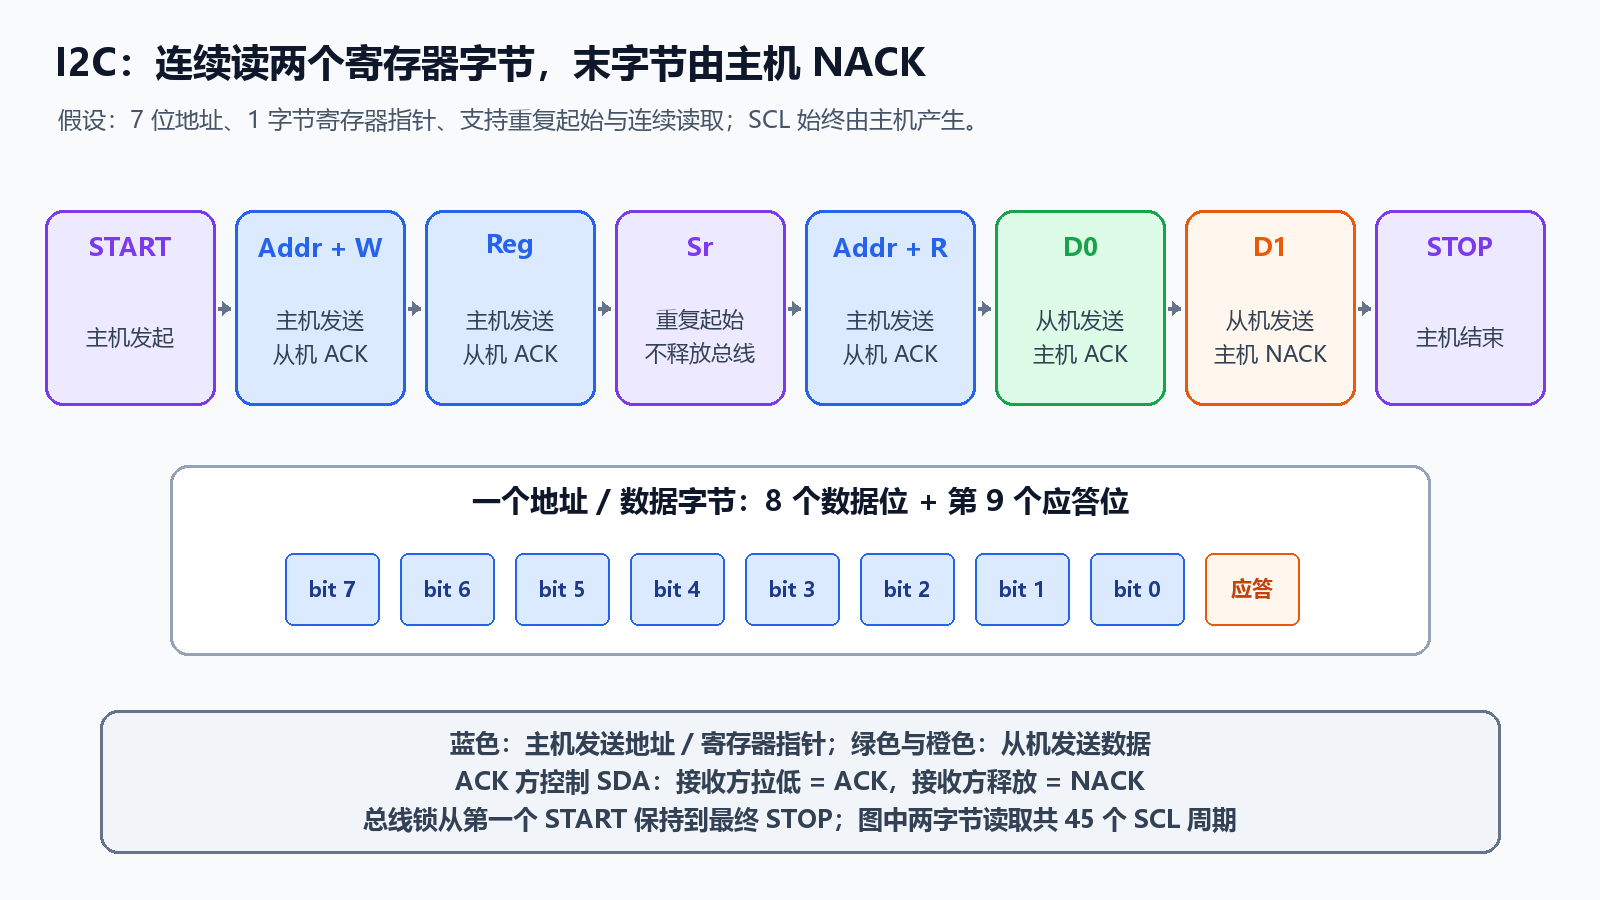

```text
写寄存器：S → Addr+W → ACK → Reg → ACK → Data → ACK → P
读寄存器：S → Addr+W → ACK → Reg → ACK → Sr → Addr+R → ACK
          → D0 → 主机 ACK → D1 → 主机 NACK → P
```

`S` 是 START，`Sr` 是重复起始，`P` 是 STOP。重复起始不释放总线，保持“设置寄存器指针 → 读取该位置”的连续性。是否允许在写指针后 STOP、是否支持地址自动递增、寄存器地址是 8 位还是 16 位，都由设备手册决定。

一段“读寄存器”操作必须从第一个 START 到最终 STOP 持有总线所有权。若只给每个字节上锁，另一个任务可以在中间改写设备寄存器指针，导致数据来自错误位置。

假设一个 7 位设备、1 字节寄存器地址、读取 N 字节，不计起止间隔和拉伸，共有 `3+N` 个带应答的字节，约 **`27+9N` 个 SCL 周期**。读两字节是 45 个周期，400 kHz 下理想时钟占用 112.5 μs。实际事务还包括软件延迟、START/STOP 时序和可能的拉伸。

设备可能使用命令帧而非寄存器模型，屏幕也可能通过控制字区分命令和数据。总线接口负责发字节，设备驱动负责决定这些字节的意义。


## 7. 软件 I2C：用 GPIO 复现电气动作

课程软件实现使用 PB6/SCL、PB7/SDA。GPIO 模拟时它们是普通开漏输出；硬件 I2C 才切换为复用功能。先开 GPIO 时钟、预置输出锁存为释放，再配置开漏，并检查两线实际状态，减少初始化误发起始信号的机会。

```c
/* GD32F4xx SPL 的 GPIO 配置片段；总线时序和错误处理另行实现。 */
rcu_periph_clock_enable(RCU_GPIOB);
gpio_bit_set(GPIOB, GPIO_PIN_6 | GPIO_PIN_7);  /* 预置为释放 */
gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT, GPIO_PUPD_NONE,
              GPIO_PIN_6 | GPIO_PIN_7);
gpio_output_options_set(GPIOB, GPIO_OTYPE_OD, GPIO_OSPEED_50MHZ,
                        GPIO_PIN_6 | GPIO_PIN_7);
```

`GPIO_OSPEED_50MHZ` 是 GPIO 驱动特性配置，**不是 I2C 总线频率 50 MHz**。I2C 实际速率由软件的低/高电平时序、读取/写入开销和拉伸决定。

本篇约定四个板级动作：`bb_sda_low()` 拉低 SDA；`bb_sda_release()` 释放 SDA；`bb_scl_low()` 拉低 SCL；`bb_scl_high_wait(limit)` 释放 SCL，并在同一事务期限内等待实际 SCL 变高。`bb_timing_delay()` 提供经验证的建立/保持延迟，也应服从期限；`bb_sda_read()` 读实际电平。

发送 8 位的学习片段如下。进入和退出时 SCL 为低，SDA 开漏且由本机控制；调用者负责 START、ACK 和 STOP。`limit` 的定义见第 13 节。

```c
/* 应用接口片段，不是可直接链接的完整软件 I2C 库。 */
static bool bb_write8(uint8_t byte, const app_limit_t *limit)
{
    for (unsigned bit = 0; bit < 8u; ++bit) {
        if ((byte & 0x80u) != 0u) bb_sda_release();
        else                     bb_sda_low();
        if (!bb_timing_delay(limit)) return false; /* SDA 建立时间 */
        if (!bb_scl_high_wait(limit)) return false;
        if (!bb_timing_delay(limit)) return false; /* 实际 SCL 高期间 */
        bb_scl_low();
        if (!bb_timing_delay(limit)) return false; /* SCL 低期间 */
        byte = (uint8_t)(byte << 1);
    }
    return true;
}
```

空循环延时会受优化、主频和中断影响。要用适合该工程的计时实现，并用逻辑分析仪/示波器核对。中断延迟通常会拉长电平阶段；是否仍合法取决于外设的最大等待和超时要求。不要为模拟总线把整个长事务关中断。


## 8. 软件 I2C：应答、读取、起止都要释放得正确

写完 8 位后，发送方必须在第 9 个时钟前释放 SDA，让接收方应答。若主机还拉低 SDA，读到的“ACK”可能是自己制造的。

```text
读取从机 ACK：
SCL 低 → 释放 SDA → 满足建立时间 → 释放 SCL并等待实际高
→ 采样 SDA（低=ACK，高=NACK）→ 满足高保持时间 → 拉低 SCL

读取数据字节：
先释放 SDA → 重复 8 次：低阶段等待 → 释放 SCL并等实际高
→ 采样 SDA并移入结果 → 高阶段等待 → 拉低 SCL

发送主机应答：
前面字节：SCL 低时拉低 SDA，产生第9时钟，随后拉低SCL并释放SDA
最后字节：SCL 低时释放 SDA，产生第9时钟，随后拉低SCL
```

建议应答函数返回独立状态 `ACK`、`NACK`、`TIMEOUT`，不要把“时钟未拉高”也当作 NACK。错误定位需要区分没人应答和总线被拉低。

| 动作 | 必须遵守的顺序 |
|---|---|
| 初次 START | 释放两线并确认空闲 → SCL 高期间拉低 SDA → 保持 → 拉低 SCL |
| 重复 START | SCL 低时释放 SDA → 释放 SCL且确认高 → 拉低 SDA → 保持 → 拉低 SCL |
| STOP | SCL 低时拉低 SDA → 释放 SCL且确认高 → 释放 SDA → 等待总线空闲时间 |

STOP 不是随便把两根线都写 1。如果先释放 SDA、后释放 SCL，SDA 上升时 SCL 还是低，未必形成有效 STOP。

本篇 GPIO 模拟以**单主机**为前提，未实现完整多主机仲裁。若要支持多主机，发送 1 时还必须监测 SDA、处理仲裁失去和时钟同步，不能把简单软件例直接放进多主机系统。


## 9. 硬件 I2C：引脚复用、时钟、工作模式

课程硬件例选择 **I2C0、PB6/SCL、PB7/SDA、AF4**。先确认板子确实连接这些脚，没有被其他模块占用；本机引脚可用性仍以具体封装和复用表为准。

```c
/* GD32F4xx SPL 初始化片段：省略应用层锁、错误状态与自检。 */
rcu_periph_clock_enable(RCU_GPIOB);
rcu_periph_clock_enable(RCU_I2C0);

gpio_af_set(GPIOB, GPIO_AF_4, GPIO_PIN_6 | GPIO_PIN_7);
gpio_mode_set(GPIOB, GPIO_MODE_AF, GPIO_PUPD_NONE,
              GPIO_PIN_6 | GPIO_PIN_7);
gpio_output_options_set(GPIOB, GPIO_OTYPE_OD, GPIO_OSPEED_50MHZ,
                        GPIO_PIN_6 | GPIO_PIN_7);

i2c_deinit(I2C0);
i2c_clock_config(I2C0, 400000u, I2C_DTCY_2);
/* 按实际 SDK 配置普通 I2C/本机地址参数，然后使能。 */
i2c_enable(I2C0);
i2c_ack_config(I2C0, I2C_ACK_ENABLE);
```

这里先使能外设时钟，再访问复位/配置寄存器。实际工程还要检查复位状态、ACK 位置默认值、本机从机地址与模式配置、初始化后线电平、PCLK1 以及所有外设是否支持 400 kHz。

硬件 I2C 自动产生部分时序，软件仍负责状态推进、错误退出、接收尾部和事务所有权。`i2c_enable()` 不意味着一次读写已经完成。

I2C0 的时钟来自 PCLK1。手册中的时钟控制值 `CLKC` 与 SCL 关系为：

```text
标准模式：fSCL = fPCLK1 / (2 × CLKC)
快速模式，duty=2：fSCL = fPCLK1 / (3 × CLKC)
快速模式，duty=16/9：fSCL = fPCLK1 / (25 × CLKC)
```

示例 `PCLK1=42 MHz`：100 kHz 标准模式 `CLKC=210`；400 kHz、duty=2 时 `CLKC=35`。**这里不是 `(CLKC+1)`，也不是 TIMER 的时钟倍频公式。** 同时要配置外设时钟频率字段和上升时间字段；库函数如何取整、范围限制是什么，应核对实际 SDK。

只设置时钟除数不能修复慢上升沿。先让电气条件满足，再选择合适时序。换系统主频或低功耗恢复后，也应重审相关时钟配置。


## 10. 硬件 I2C 标志：可写、可读、完成不能混用

| 标志 | 含义 | 软件动作 / 注意 |
|---|---|---|
| SBSEND | START 已发送 | 按手册读 STAT0 后写 DATA，进入地址发送 |
| ADDSEND | 主机地址发送并得到 ACK；从机时表示地址匹配 | 主机按规定读 STAT0 再读 STAT1 清除；短读前需先配置 ACK |
| TBE | 发送 DATA 缓冲为空 | 可以写下一个字节，未必最后一位已发送 |
| BTC | 字节传输阶段完成 | 发送末尾需等待；接收时两级缓冲占满也可置位 |
| RBNE | 接收 DATA 缓冲非空 | 才能读取 DATA；不是“为空才接收” |
| I2CBSY | 总线忙 | 初次 START 前和事务结束后有界检查 |
| STPDET | 从机检测到 STOP | 不是主机 STOP 请求完成标志 |
| AERR | 没收到 ACK | 按阶段区分地址/数据 NACK；处理错误退出 |
| BERR / LOSTARB / OUERR | 总线错误 / 仲裁失去 / 溢出 | 记录并按规定恢复，不能继续当正常数据收发 |

**读寄存器可能有副作用。** ADDSEND 的清除需要两次规定顺序的读取，会释放某些被硬件暂停的进程。调试器自动刷新状态窗口，或日志函数额外读 STAT1，可能改变程序行为；不要把所有状态寄存器都当纯观察值。

清标志也不能统一写 1：SBSEND、ADDSEND、STPDET 有规定访问序列；一些错误位按写 0 清。优先用匹配 SDK 的接口，并核对它到底如何访问寄存器。

课程可见等待片段用循环次数计数，例如 50000 次。其耗时受主频、编译优化和中断影响。本篇使用事务共享的单调计时预算，见第 13 节。


## 11. 硬件 I2C 写事务：最后要等字节真的发送完成

以单主机写一个寄存器和 N 个数据字节为例，流程应当连贯：

```text
获取总线锁，设定本次总预算
→ 检查 BUSY 为 0、两线空闲
→ 请求 START，等待 SBSEND
→ 按地址格式发送写地址，等待 ADDSEND，同时检查 AERR/BERR/LOSTARB
→ 按规定清 ADDSEND
→ 等 TBE，写寄存器地址
→ 对各数据字节：等 TBE，写 DATA，所有等待都检查错误和同一期限
→ 最后等待 BTC（不是只等 TBE）
→ 请求 STOP，有界确认请求完成/总线释放
→ 归还总线锁，返回完整结果
```

读寄存器前的“写寄存器地址”阶段也走发送路径。最后等待 BTC 后，若设备要求连续读，则发重复 START 而非 STOP；然后进入读地址与接收流程。

接口返回值应包含至少：成功、参数错误、地址 NACK、数据 NACK、超时、总线错误、仲裁失去。可另带已完成字节数和当前阶段，帮助排查。

一个写事务超时，不意味着设备完全没执行。有些字节可能已经被接受。写“清中断”“触发一次转换”“加入队列”等命令时，无条件重试可能重复执行。**能否重试由设备驱动按命令语义判断**，总线层不默认把所有操作重复三遍。

空数据长度也要约定：它是非法参数、只写寄存器指针，还是地址探测？不要让数组长度为零自动走到含义模糊的硬件状态。


## 12. 硬件 I2C 读事务：1、2、3 个字节的尾部不同

GD32F4xx I2C 有数据寄存器和移位寄存器，ACK 策略影响的是正在接收或随后接收的字节。不能写成“循环读完全部数据，再关闭 ACK”。那时最后一字节的应答可能早已发出。

本篇采用官方手册第 559～560 页的 **主机接收 Solution B**：利用 BTC 和硬件暂停接收的阶段安排结尾。表中是 7 位寻址时的数据接收策略；完整驱动仍需处理地址阶段、错误和清理。

| 长度 | 地址阶段 | 数据和结束阶段 |
|---|---|---|
| N=1 | 正常 ACK 位置；在清 ADDSEND **之前**关闭 ACK | 清 ADDSEND 后请求 STOP，再等 RBNE 读 1 字节 |
| N=2 | 在读方向的 START **之前**设置 POAP；在清 ADDSEND 前关闭 ACK | 等 BTC，请求 STOP，连续读 DATA 两次 |
| N>2 | 正常 ACK 位置，ACK 开启，按规定清 ADDSEND | 先正常收 N−3 字节；最后 3 字节按下面流程结束 |

剩余 3 字节时，记它们为 `a=N−2`、`b=N−1`、`c=N`：

```text
等 BTC：a、b 已占满接收缓冲，硬件暂停继续接收
→ 关闭 ACK → 读 a，允许继续接收 c
→ 再等 BTC：b、c 已在缓冲
→ 请求 STOP → 读 b → 读 c
```

N=3 时，前面“正常读 N−3 字节”就是读零个字节，直接进入尾部；N=4 时先读一个。N=2 的 POAP 配置应在**读方向的 START/重复 START 前**完成，不能等地址 ACK 后才想起改位置。

清 ADDSEND/请求 STOP、关闭 ACK/读数据、请求 STOP/连续读两字节等关键动作，要按手册安排必要的**短临界区**。等待 BTC/RBNE 的长轮询应在临界区外并保持超时处理；不要整个读操作关中断。

正常结束或错误退出后，都要按受控恢复流程把 ACK、POAP、接收残留和外设状态恢复到约定基线，确认 STOP/总线释放再交还所有权。否则一次两字节读取留下的 POAP，会影响下一次一字节读取。

这是学习中最应上板验证的部分：分别抓取 **1、2、3、4、较长**读事务，确认只有末字节 NACK、没有多读、STOP 正确、随后新事务仍可运行。寄存器状态正确也需要与线上波形对应。


## 13. 统一超时：每个等待都检查错误，共享一个预算

给每个字节重新启动一个 100 ms 超时，1000 字节最坏可能等 100 秒。更明确的做法是：整笔事务建立一次预算，所有状态等待、时钟拉伸和清理受其约束；清理若需单独小预算，应在 API 最大总耗时中计算。

下面为独立 C99 的无符号差值计时。`start_us` 来自活动期间可靠递增的微秒时基；传输中该时基不能因调日历或时钟切换突然改变。

```c
#include <stdint.h>
#include <stdbool.h>

typedef struct {
    uint32_t start_us;
    uint32_t budget_us;
} app_limit_t;

static bool app_limit_expired(const app_limit_t *limit, uint32_t now_us)
{
    return (uint32_t)(now_us - limit->start_us) >= limit->budget_us;
}
```

工程约定：指针有效；`0 < budget_us < 0x80000000`；等待期间持续检查，不能跨过完整回卷周期。32 位微秒计数约 **71.58 分钟**回卷，无符号减法可处理一次边界跨越。例如 `start=0xFFFFFFF0`，`now=0x20`，实际经过 48 μs。

等待逻辑的优先级示意：

```text
循环：
  先取必要状态，检查 NACK / 总线错误 / 仲裁失去 / 溢出
  有错误 → 记录阶段与状态，转受控退出
  所等条件已满足 → 返回成功
  同一事务预算已耗尽 → 返回超时
  让出适量执行机会或继续短轮询（按时序要求选）
```

实际 API 应规定超时边界和状态同时到达时如何判断。不要为了打印日志反复读有清标志副作用的寄存器；先用适当方法保存必要证据，再退出。

错误退出的原则是 **记录原因 → 判断总线所有权 → 结束/中止本机状态 → 有界检查线路 → 必要恢复 → 还锁**。仲裁失去后，其他主机可能正在使用总线，不能随意发送 STOP 或恢复脉冲；单主机假设也不能掩盖错误标志。

看门狗只负责最后的故障监督，不能替代这些预算。若等待中无条件喂狗，永久卡住的通信可能一直“存活”。


## 14. I2C 总线恢复：先检查谁在拉低

“BUSY 一直置位”有不同原因：外设正在合法传输、SCL 被拉伸、接线短路、从机停在半字节阶段、MCU 状态异常。先读取实际 SCL/SDA，并核对上电和复位顺序。

| 线路状态 | 可能方向 | 处理重点 |
|---|---|---|
| 两线高，硬件仍报忙 | MCU 状态/配置异常 | 按芯片手册处理状态与外设重初始化 |
| SCL 低 | 拉伸、短路、未供电器件影响、驱动冲突 | 有界等待与电气排查，不能强推高 |
| SCL 高，SDA 低 | 从机可能等待后续时钟，或 SDA 短路 | 单主机且所有权确认后，可尝试受限总线清除 |
| 两线低 | 正在进行事务或线路故障 | 先确认状态，不能直接重试 |

学习用的单主机恢复流程：停止本机事务与 DMA/中断，保持总线锁，禁用硬件 I2C，切为开漏 GPIO并释放；若 SCL 无法在期限内变高，停止脉冲尝试。若 SCL 可高而 SDA 低，可以在释放 SDA 的情况下产生**至多 9 个受限时钟脉冲**，每次确认实际 SCL 高并检查 SDA 是否释放；随后按正确顺序尝试 STOP，确认两线高，再恢复复用和外设配置。

不要把“9 个脉冲”写成一定修复。有的器件要复位或重新上电；SCL 被持续拉低时，主机无法正常产生这些时钟。恢复过程中也不能让第二个任务进入总线。

总线清除仅用于已确认的单主机系统或明确取得恢复权限的场景。它会改变外设协议状态，可能使半完成写入变成部分生效。成功恢复后，设备驱动应重新建立配置、寄存器指针和有效性状态，**不直接将之前半包当有效数据使用**。

若准备通过外设复位或断电恢复，还要考虑同总线其他器件是否共享电源/复位，以及未供电设备是否通过信号线被反向供电。恢复策略应有次数限制和可观察的失败结果。


## 15. I2C 时钟案例：PCF8563 是外置 RTC

课程 I2C 时钟案例使用 **PCF8563**，迁移 `PCF8563.h/.c` 并替换底层 I2C 依赖。它通过总线与 MCU 通信，和第 07 篇的 MCU 内置 RTC/备份域是两个独立对象。

| 层次 | 负责什么 |
|---|---|
| 总线层 | 在指定设备地址上读写一段字节，执行重复起始与超时 |
| PCF8563 驱动 | 寄存器布局、BCD、状态位、时间更新/读取规则 |
| 时间服务 | 判断时间可信度、校时、时区与业务事件 |
| 显示层 | 将有效时间格式化为用户可读内容 |

迁移时先搜索设备驱动使用的底层函数：START、发送字节、等待应答、读取、STOP、延时。用清晰的总线接口替换，而不是把所有平台宏散落到每个时间函数里。

推荐提供这样的应用契约：

```c
/* 应用接口声明：实现需按实际器件手册核对地址、寄存器与更新规则。 */
app_status_t pcf8563_read_time(pcf8563_t *dev, app_calendar_t *time,
                               const app_limit_t *limit);
app_status_t pcf8563_set_time(pcf8563_t *dev, const app_calendar_t *time,
                              const app_limit_t *limit);
```

读时间时不要逐字段跨多次总线读取后直接拼接；在秒进位处可能形成不一致日期。应按器件支持的连续读取/冻结规则获取一致快照，再屏蔽状态位、校验 BCD 和范围。秒寄存器里的电压低/时间无效标志不能当普通秒值的一部分；读到合法 BCD，也不等于时间可信。

设置时间前要验证年月日与闰年，并按器件要求控制计时/更新，避免写到一半发生进位。星期编码、世纪位和年份范围也要通过设备驱动归一化，不能直接套用内置 RTC 的字段编码。

本篇未取得可读的 PCF8563 完整数据手册，**不把具体地址、寄存器表和世纪位策略作为已核对的移植参数**。实际实现前应以模块对应芯片手册确认，并测试 23:59:59、月末、闰日和电源异常。这里重点是驱动迁移与总线事务，不提供声称已可运行的日历工程。


## 16. I2C 屏幕案例：通信成功还要检查设备协议

课程 I2C 屏幕例使用 PB6/PB7，并出现外部 10 kΩ 上拉；按第 3 节核对负载和速度。接线正确、地址 ACK，也只能证明总线已有应答，不能证明屏幕初始化正确。

常见 OLED 驱动需要区分命令和像素数据，某些 I2C 控制器通过一个控制字告诉设备后续字节类型。以下只表示协议结构：

```text
命令事务：START → 写设备地址 → 控制字（命令）→ 初始化/定位命令 → STOP
数据事务：START → 写设备地址 → 控制字（数据）→ 显存数据块 → STOP
```

控制字、地址、页寻址方式和初始化参数由实际控制器决定，不能见到 OLED 就默认是同一型号。分辨率、列偏移、扫描方向、电荷泵和复位方法，也会影响画面。

若一个 **128×64、1 bit/像素、按页存储**的模块，每 8 行为一页，则缓冲可为 8 页 × 128 列 = **1024 字节**。一个字节的各位代表同一列的不同像素行；这和把每个像素存一个完整字节不同。

```c
/* 对“页=8行、列按字节存储”的假设布局有效；未等同于所有屏幕协议。 */
uint8_t frame[8][128];

void frame_pixel(unsigned x, unsigned y, bool on)
{
    if (x >= 128u || y >= 64u) return;
    uint8_t mask = (uint8_t)(1u << (y & 7u));
    if (on) frame[y >> 3][x] |= mask;
    else    frame[y >> 3][x] &= (uint8_t)~mask;
}
```

绘图函数修改缓冲，刷新函数将缓冲发送到设备。先验证一页、全黑、全白、棋盘格和方向，再加入汉字字模。汉字编码警告应通过统一源文件/字库编码和确认字模索引处理；直接忽略警告无法保证显示正确。

如果 1024 个像素数据在一个事务中发送，按“地址 + 1 个控制字 + 数据”估算：`9×1026=9234` 个 SCL 周期，400 kHz 下约 **23.085 ms**，未计定位命令和软件开销。若每个字节都单独起止，开销会显著增加。刷新期间也需要考虑同总线传感器的响应时间。

屏幕显存、字库、触摸和界面将在第 11、12 篇深入。本节先掌握总线与设备命令的分工。


## 17. SPI 接线：信号方向和片选

普通四线 SPI 由主机产生 SCK，通过 MOSI 发数据，通过 MISO 收数据，用 CS 选择一个从机。

| 信号 | 主机侧方向 | 从机侧方向 | 常见名字与注意 |
|---|---|---|---|
| SCK | 输出 | 输入 | SCLK、CLK；时钟模式需一致 |
| MOSI | 输出 | 输入 | Controller Out / Peripheral In；SDI 需看器件视角 |
| MISO | 输入 | 输出 | Controller In / Peripheral Out；SDO 需看器件视角 |
| CS / NSS | 通常 GPIO 输出 | 片选输入 | 常见低有效，但以器件手册为准 |
| GND | 共参考地 | 共参考地 | 未共地时逻辑电平没有正确参考 |

模块标 `SDO` 表示“这个模块的数据输出”时，它应连接主机 MISO；若主机接口自身标 SDO，方向可能对应 MOSI。不要在所有器件上机械套用 `SDO=MOSI`。有些 SPI 屏幕把 CLK/MOSI 标为 SCL/SDA，**只有两根类似 I2C 的名字，也不能据此判断协议**，要结合 CS/DC/RES 与器件手册。

多个从机通常共享 SCK、MOSI、MISO，各有独立 CS。任何时刻只选择一个；未选从机的 MISO 必须不干扰共享线。上电时先将全部 CS 置为未选状态，必要时按板级电路设置上拉，以免启动过程中误发命令。

有些屏幕只接 MOSI、不返回数据；有些器件支持半双工单数据线，有些支持菊花链。这些都需要器件和控制器配置明确支持，不能把普通四线例直接改接后认为自动兼容。

SPI 推挽时钟也受驱动、走线、负载和地回路影响。长飞线、高速边沿可能导致过冲、振铃和串扰；逻辑分析仪看出时序，示波器才能进一步确认电压与边沿质量。


## 18. SPI 四种模式：CPOL 和 CPHA 要一起看

`CPOL` 决定 SCK 空闲电平；`CPHA` 决定在一个位周期的第一个还是第二个边沿采样。GD32 手册分别使用 `CKPL`、`CKPH` 名称。

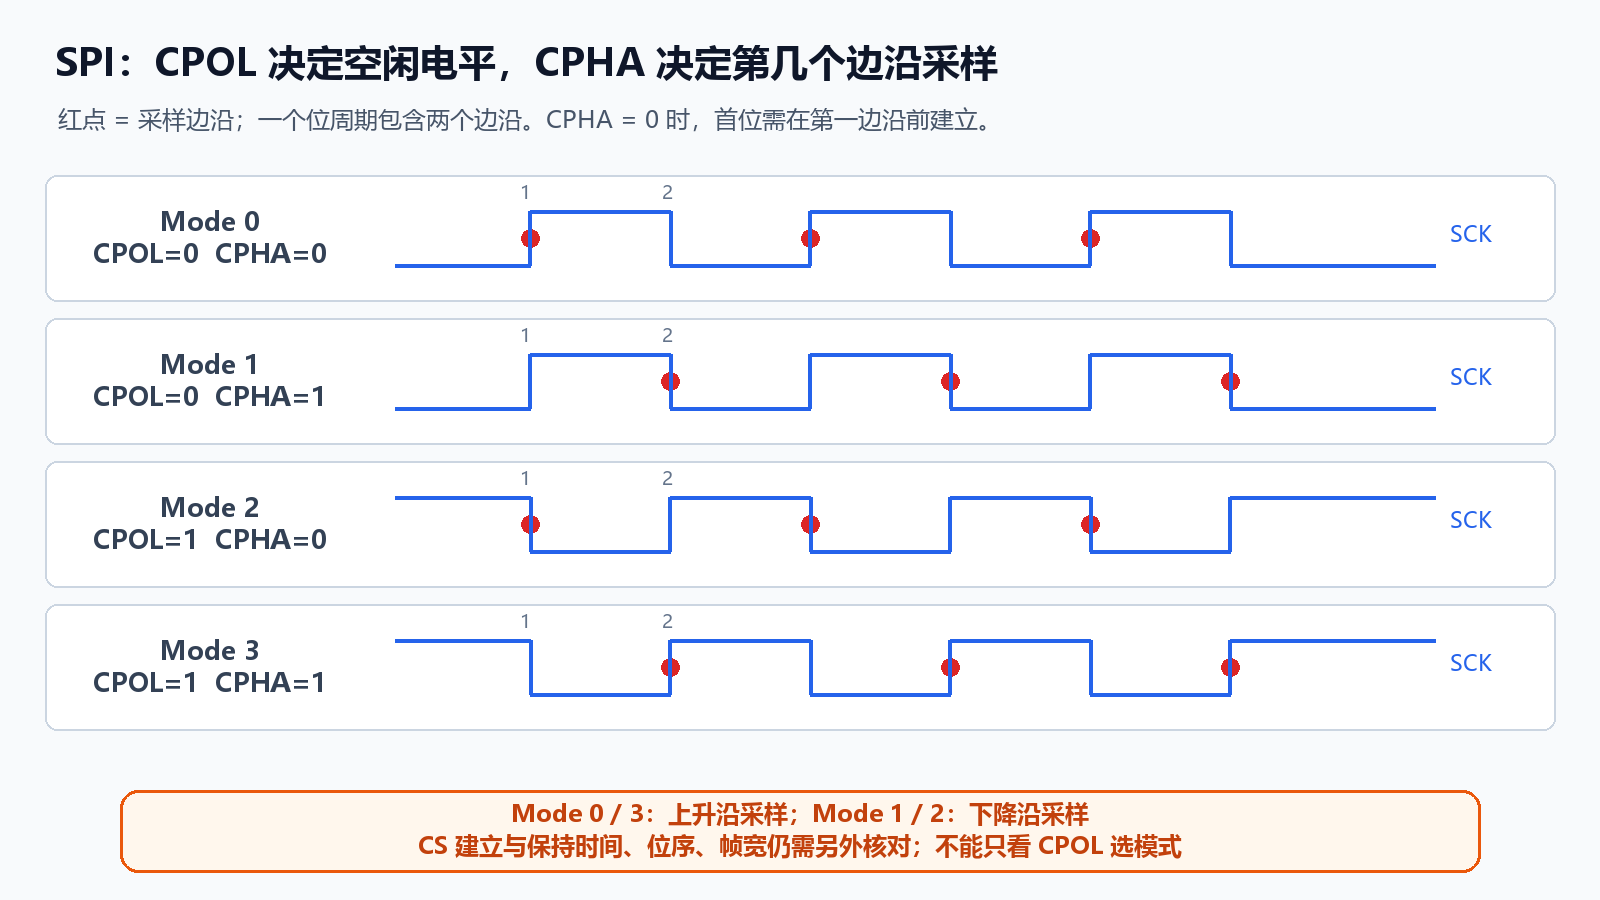

| 模式 | CPOL | CPHA | 空闲 SCK | 第一个边沿 | 采样边沿 | 常规数据更新边沿 |
|---|---:|---:|---|---|---|---|
| Mode 0 | 0 | 0 | 低 | 上升 | 上升 | 下降 |
| Mode 1 | 0 | 1 | 低 | 上升 | 下降 | 上升 |
| Mode 2 | 1 | 0 | 高 | 下降 | 下降 | 上升 |
| Mode 3 | 1 | 1 | 高 | 下降 | 上升 | 下降 |

CPHA=0：第一边沿就要采样，因此第一位数据必须在第一边沿前建立。CPHA=1：第一边沿用于推出/更新数据，第二边沿采样。之后数据按相反边沿更新，保证采样附近稳定。

**CPOL=0 不等于一定上升沿采样；CPOL=1 也不等于一定下降沿采样。** 只看 CPOL 会遗漏 CPHA。课程原理页的详细四模式表可用，但单独根据 CPOL 推断采样方向的说法需要修正。

移植时把设备手册里的“空闲电平、采样边沿、数据建立时间”转换到上表，再配置主机；不要只根据别人例程写了“模式0”就直接照搬。如果设备允许多种模式，仍要确保所选模式及 CS 时序满足其规定。

模式错误可能出现错一位、读值偶尔正确、低速正常高速异常等表现。降低频率有时只是掩盖时序问题，应抓取 CS/SCK/MOSI/MISO，并按实际采样边沿检查。


## 19. SPI 是全双工移位：读取也要发送时钟

普通全双工 SPI 每产生一个时钟，主机和从机各移出一位，同时接收另一方向的一位。8 位帧需要 8 个时钟；16 位帧需要 16 个时钟。

```text
主机写 TX = 0xA5
→ 产生 8 个 SCK
→ MOSI 输出 0xA5 的各位
→ 同一段时钟内 MISO 的 8 位进入 RX
```

因此底层原语更适合叫 **exchange / 交换**，而不只是“发送”。主机想读取时，通常写一个设备允许的 dummy 字节以产生 SCK；若从不写 DATA，只等待 RBNE，可能永远没有新时钟和新数据。

| 操作 | TX | RX |
|---|---|---|
| 发送 | 写真实命令/数据 | 全双工时仍需读取/丢弃接收数据 |
| 接收 | 按设备协议写 dummy | 保存对应接收数据 |
| 收发 | 写真实数据 | 保存真实返回数据 |

dummy 值是设备协议的参数，可能是 0x00、0xFF 或其他值，并非全 SPI 标准统一规定。命令阶段返回的字节也可能无意义，需要丢弃；寄存器读取的有效值可能出现在地址后的第一个或更后的帧。

例如某器件约定 `命令+寄存器地址+dummy+数据`，读 2 字节的发送序列也许是 `cmd, reg, dummy, dummy, dummy`，返回前几字节丢弃，最后两字节保存。这个例子只说明阶段与对齐，**不是所有器件的通用命令格式**。

全双工模式中只发送不读 RX，可能产生 `RXORERR`。即使 OLED 没接 MISO，也要按所选模式处理接收路径，或明确配置为适用的只发送模式。不能以“外设不返回有用数据”为由忽略硬件 RX 缓冲。


## 20. 位序、端序与帧宽：不要混成一个设置

位序说明一个帧中哪一位先发；多字节端序说明一个数值的哪个字节先发。它们是不同层次。

假设要按设备协议发送数值 `0x1234`，并要求高字节先发送、每个字节 MSB first：

```c
/* 显式序列化，比直接发送内存布局更清楚。 */
uint16_t value = 0x1234u;
uint8_t bytes[2] = {
    (uint8_t)(value >> 8),
    (uint8_t)(value & 0xFFu)
};
```

实际先发 `0x12`，再发 `0x34`。对小端 CPU，直接发送 `&value` 指向的两个内存字节可能是 `0x34,0x12`。**MSB first 不会替你交换内存中的两个字节。**

| 配置 / 属性 | 影响 |
|---|---|
| MSB/LSB first | 每帧内部位顺序 |
| 8/16 位帧 | 一次 DATA 访问和时钟帧宽 |
| 协议端序 | 数值在连续字节中的排列 |
| DMA 内存与外设宽度 | 每次搬运的单位、对齐、计数和地址步进 |

16 位 SPI 并不自动表示所有多字节设备都能这样传输；有的命令阶段是 8 位，有的依赖精确 CS/帧边界。切换帧宽前必须先让传输结束，并符合器件协议。

屏幕 RGB565 的 16 位颜色也需要核对传输字节顺序。若颜色不对，先检查字节交换与像素格式，再检查 RGB/BGR 等显示设置，不要只改位序碰运气。


## 21. GD32 硬件 SPI：配置与频率

课程查询页给出一组引脚：**SPI0 的 PA5/SCK、PA6/MISO、PA7/MOSI、PA4/NSS**。本篇采用前三根作为硬件数据/时钟，PA4 可作为 GPIO CS；不要同时把同一脚配置成 AF NSS 和普通 GPIO CS。

常见对应 AF5，实际应核对 **GD32F407VET6 的封装/复用表**再写配置。SPI0/1 等编号也不是每套平台相同：GD32 的 SPI0 对应名字不能机械照搬到 STM32 的 SPI1。

配置顺序：

1. 使能 GPIO 与 SPI 外设时钟，预置所有 CS 未选。
2. 配置 SCK/MOSI/MISO 对应复用；主机输出采用设备和板级允许的推挽速度。
3. 禁用/复位 SPI，在空闲状态配置主机、全双工、8 位、位序、CPOL/CPHA、分频和软件 NSS。
4. 使用软件 NSS 时设置内部 NSS 为高，避免主机配置错误。
5. 清理旧状态，使能 SPI，自检后再开始具体设备事务。

这是配置流程，不是完整可复制工程。库结构体字段、常量与函数名称以匹配 SDK 为准；不要将系列手册中的最大外设数量当作具体型号都支持的数量。

手册规定：SPI0/3/4/5 的外设时钟来自 PCLK2，SPI1/2 来自 PCLK1；这些是系列规则，实际存在的实例以本机为准。普通 SPI 分频 `D=2,4,8,…,256`：

```text
fSCK = fPCLK / D
```

例如 SPI0 的 `PCLK2=84 MHz`，目标不超过 10 MHz：除以 8 得到 10.5 MHz，超过目标；应选除以 16 得到 **5.25 MHz**。这时若误把 CPU 168 MHz 代入，会得到错误的波形预期。

先低速验证模式和命令，再按设备允许速度逐步提高。分频表不能表达任意频率；不同设备共享总线时，可在事务之间按设备参数重新配置，前提是总线空闲、CS 全部未选，且配置过程受总线锁保护。


## 22. SPI 的 CS 与内部 NSS：不是同一个动作

**内部软件 NSS** 是控制器判断自己是否处于合法主机状态的输入；**GPIO CS** 是实际选择外部设备的管脚。把软件 NSS 设高不会自动把 GPIO CS 拉高或拉低。

GD32 手册说明：主机软件 NSS 模式下内部 `SWNSS` 应保持高；若低，可能触发 `CONFERR`，硬件清除使能/主机配置。硬件 NSS 输出模式也不保证为每个应用事务自动产生所需脉冲，因此本篇统一用 GPIO 控制设备 CS。

一个常见低有效事务是：

```text
取得总线锁 → 确认SPI空闲、其他CS未选 → 按设备设置模式与频率
→ CS拉低 → 满足片选建立时间 → 命令/地址/dummy/数据
→ 排空接收，确认 TBE=1 且 TRANS=0 → 满足片选保持时间
→ CS拉高 → 满足事务间隔 → 释放锁
```

CS 应包围**整个设备命令**。若每发一个字节都切一下 CS，某些 Flash 或传感器会把后续地址/数据当成新命令。另一些器件要求帧间拉高，则必须按它自己的规定处理。

不要在传输进行中修改 CPOL/CPHA、帧宽或分频。改变空闲电平可能产生额外边沿；因此选择新设备之前应保证旧设备已结束且 CS 全部未选。

软件锁必须跨命令、地址和数据的完整过程，还要包含总线重配置。两个任务只锁每次 `exchange8()`，依然可能相互插入字节或在对方 CS 低期间换模式。

错误时 CS 也要受控释放。先确定硬件活动是否已结束，或按驱动策略中止/复位，确认没有继续发出的时钟后解除选中；然后按设备协议标记命令失败并必要复位状态，不让半包被下一次操作续接。


## 23. SPI 状态与 8 位交换：TBE 不代表线上结束

| 状态 | 含义 | 用途 |
|---|---|---|
| TBE | 发送缓冲为空 | 可以写下一帧，不能单凭它拉高 CS |
| RBNE | 接收缓冲非空 | 读取 DATA 取得对应接收值 |
| TRANS | 线上仍在传输 | 最后需等待为 0，再结束事务/关闭 SPI |
| RXORERR | 接收溢出 | 排查未及时读 RX、DMA 配置；按规定清除 |
| CONFERR | 主机 NSS 等配置故障 | 先修复配置及硬件状态，再按规定清除 |

官方手册第 589 页的结束条件包括：读取最后接收数据、TBE 已空、TRANS 已清。最后一帧进入移位寄存器后，TBE 可能已置位，但 SCK 还在跑。

下面是应用接口学习片段，**全部 `board_spi_*` 要由实际 GD32 驱动实现**。前提：已取得总线锁，配置正确，RX 无前次残留，8 位全双工，`limit` 非空；它只交换一帧，CS 由上层事务控制。

```c
typedef enum {
    APP_OK, APP_BAD_ARG, APP_TIMEOUT, APP_IO_ERROR
} app_status_t;

static app_status_t app_spi_exchange8(uint8_t tx, uint8_t *rx,
                                      const app_limit_t *limit)
{
    if (limit == NULL) return APP_BAD_ARG;
    for (;;) {
        if (board_spi_error()) return APP_IO_ERROR;
        if (app_limit_expired(limit, board_mono_us())) return APP_TIMEOUT;
        if (board_spi_tbe()) break;
    }
    board_spi_write8(tx);
    for (;;) {
        if (board_spi_error()) return APP_IO_ERROR;
        if (app_limit_expired(limit, board_mono_us())) return APP_TIMEOUT;
        if (board_spi_rbne()) break;
    }
    uint8_t incoming = board_spi_read8(); /* 必须读取，rx为NULL也不省略 */
    if (rx != NULL) *rx = incoming;
    return APP_OK;
}
```

事务结束时，还需用同一预算等待 TBE 和 TRANS=0、检查最后错误、满足 CS 保持时间后拉高片选。本函数返回 `APP_OK` 只表示交换已读取对应帧，不承担完整命令结束或外设业务成功。

错误标志的清除顺序也不同：`RXORERR` 按手册**先读 DATA，再读 STAT**；`CONFERR` 需要规定的 STAT 访问后写 CTL0，并重建正确的主机/使能配置；CRC 错误有自己的写清规则。不能对所有状态调用一个假定的“写1清除”。

SPI 没有统一地址 ACK。线上读到 0xFF 或 0x00 可以来自未连接、默认电平、设备未选、真实数据或协议错位。应结合型号标识、命令响应、状态字段和波形确认。


## 24. SPI 屏幕：CS、DC、RES 各有职责

课程 SPI 屏幕页给出 CS、DC、RES、CLK、MOSI 等信号。屏幕可能不需要 MISO，但设备协议通常还要求命令/数据选择和硬件复位。

| 信号 | 职责 | 常见动作 |
|---|---|---|
| CS | 选择本块屏幕 | 包围一次设备规定的传输 |
| DC | 标识当前字节是命令还是数据 | 常见低=命令、高=数据，仍须核对设备 |
| RES / RESET | 复位屏幕控制器 | 按手册脉宽与释放后等待时间操作 |
| CLK / MOSI | 传输字节 | 由 SPI 控制器产生 |

```text
按手册上电并复位
→ CS选中，DC置命令状态，发送初始化命令及相应参数
→ 设置显示地址窗口/页列位置
→ DC置数据状态，发送像素块
→ 确认最后时钟结束，解除CS
```

DC 要在相关字节开始前建立，并保持到这些字节真正发送完。若只是把字节交给 DMA 就立刻切 DC，仍在发送的字节可能被解释成另一类型。命令参数是“命令流”还是“数据流”，也需看具体控制器要求。

用 SPI0 的教学引脚组时，CS/DC/RES 可以是板上实际接到的普通 GPIO。本篇未从可见课程正文确认全部实物连线，**不猜 DC/RES 引脚和屏幕型号**，让设备结构体保存真实板级连接。

如果仍用第 16 节的 1024 字节单色缓冲，在 5.25 MHz、8 位帧下，纯像素时钟时间约 `1024×8/5.25 MHz = 1.560 ms`。实际还加命令、等待、CPU 和片选开销；这是吞吐量估算，不是屏幕实测帧率。

显示花屏要依次核对模式、帧宽、复位、初始化、位置、像素格式和缓冲长度。只换到 SPI 并不会自动让 I2C 屏幕驱动的命令布局与新控制器匹配。


## 25. DMA：搬运结束与总线事务结束仍需分开

DMA 能减少 CPU 逐字节搬运，但不会替设备选择协议，也不会代替 CS、I2C 末字节应答和错误恢复。

| 场景 | 关键要求 |
|---|---|
| SPI 全双工 DMA | 预先配置 RX/TX，通常先使 RX 能接收，再让 TX 产生时钟；两边长度/宽度匹配 |
| SPI 只写屏幕但仍用全双工 | RX 要有受控的接收/丢弃路径，不能任由溢出 |
| SPI 读设备 | TX 提供命令和 dummy 时钟，RX 对齐并丢弃无效阶段 |
| I2C DMA 写 | 完成搬运后仍按手册等待传输末尾并请求 STOP |
| I2C DMA 读 | 正确安排 ACK/NACK、DMALST、STOP；单字节有特殊规则 |

**SPI TX DMA 完成只表示源缓冲数据已交到外设路径。** 最后字节仍可能正在移出；要检查必要 RX 完成、TBE 与 TRANS，再切 CS、DC、模式或交还相关缓冲所有权。

I2C 接收 DMA 也要看长度。手册普通主机接收中，DMA 请求使能与清 ADDSEND 有规定顺序；对至少两字节的适用流程，`DMALST` 帮助让最后字节 NACK，完成后还需 STOP。单字节需在清 ADDSEND 前关闭 ACK，不能套多字节模板。实现前应结合官方手册与匹配库示例核对。

DMA 通道映射、外设地址、位宽和计数单位继承第 06 篇的检查方法。不能把 16 位搬运的“100 项”当成 100 字节，也不能让 8 位数组按 16 位递增错误跨界。

缓冲契约要明确：发起异步传输后，调用者不能随意改写源缓冲或读取未完成目标；在成功/错误终止回调后再归还所有权。若所用型号有缓存或特殊内存访问限制，需按它的规则处理，不能把系列能力混为本机事实。

使用中断/DMA 后，I2C/SPI 的错误回调要能终止双方搬运、解除状态占用、返回可观察结果。成功完成标志和错误标志同时出现时，应先按驱动的明确策略判断错误，不能只因为 DMA 满了就交付数据。


## 26. 驱动分层：换总线不应重写所有应用

设备协议和总线传输分开后，软件 I2C 可以换硬件 I2C，屏幕/时间服务也更容易复用。

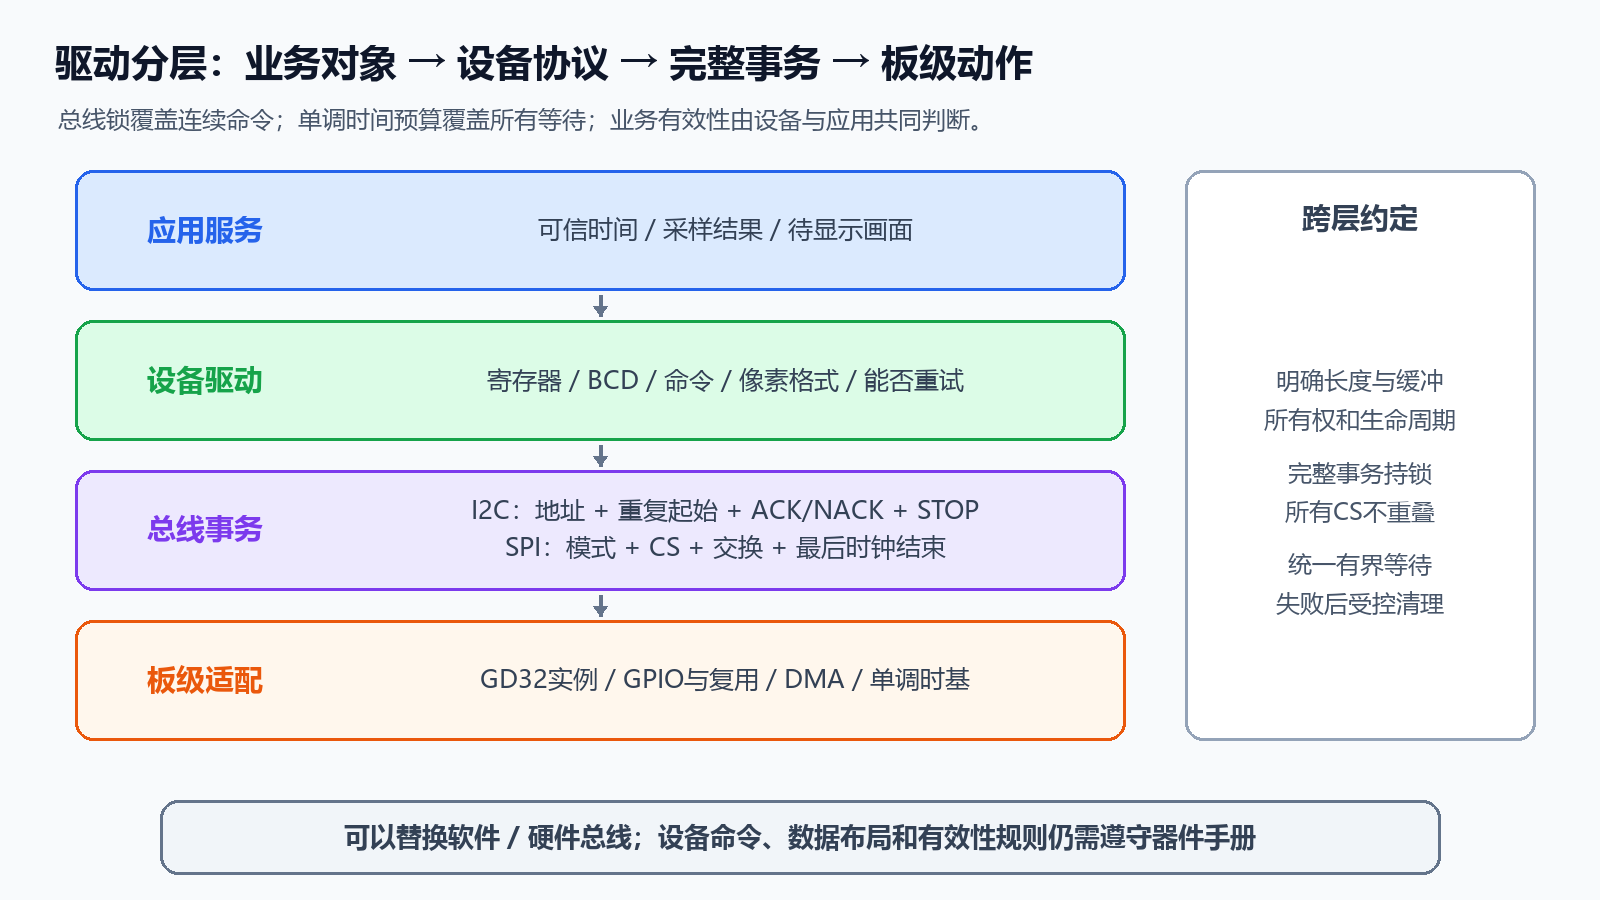

| 层次 | 输入/输出 | 不宜承担的职责 |
|---|---|---|
| 应用服务 | 时间、温度、屏幕画面等业务对象 | 直接拼每个 START/ACK 或逐次配置 SPI 寄存器 |
| 设备驱动 | 地址、命令、寄存器、像素格式、有效性 | 把 I2C 某引脚写死在每个设备函数 |
| 总线事务 | 连续字节序列、方向、期限、状态 | 猜设备命令是否可以重试、解释所有业务值 |
| 板级适配 | 外设实例、复用、GPIO、时基、锁 | 在底层延时里偷偷改变应用状态 |

可让 I2C 设备保存总线引用和统一 7 位地址；SPI 设备保存总线引用、CS 回调、模式、最大 SCK、位序与片选时序。总线层在锁内应用设备参数，完成整个事务，再返回状态。

对于寄存器访问，推荐明确参数：`reg_width`、寄存器字节序、TX/RX 长度、是否重复起始、最大耗时。长度必须与缓冲容量一致，不能让驱动靠终止符推断二进制包长。

错误可以逐层增加语境，例如：`I2C address NACK → PCF8563 read_time失败 → 时间服务标记无效`。应用获得的是“没有可信时间”，不是继续显示上一包并冒充当前成功读取。

共享总线的锁不要在 ISR 中长时间等待；ISR 提交事件，主循环/任务做事务。异步驱动还需要清晰的忙状态、队列和取消政策，否则 API 返回后缓冲可能已经失效。


## 27. 通信吞吐量：先算量，再决定优化

先用可解释的模型估算，再上板测量。不要用“SPI 更快”代替数据量、刷新周期和延迟的具体计算。

| 场景 | 计算 | 理想时钟时间 |
|---|---|---|
| I2C，1 字节寄存器指针，读 2 字节，400 kHz | `(27+9×2)/400000` | 112.5 μs |
| 同样读取，100 kHz | `45/100000` | 450 μs |
| I2C，1024 数据 + 地址 + 控制字，400 kHz | `9×1026/400000` | 23.085 ms |
| 同样发送，100 kHz | `9234/100000` | 92.34 ms |
| SPI，1024 数据，5.25 MHz | `8×1024/5250000` | 1.560 ms |
| SPI，1024 数据，1 MHz | `8192/1000000` | 8.192 ms |

这些数值不含额外命令、软件间隔、CS 建立/保持、I2C 拉伸和总线空闲要求。SPI 全双工同步收发 N 字节，时钟仍是 `8N`，不能把 TX 和 RX 相加误算成 `16N`；但若协议先发命令再读数据，那各阶段长度需合计。

想每秒刷新 30 次，周期约 33.33 ms。I2C 400 kHz 下仅理想全屏数据就占 23.085 ms，约 **69.255%** 周期；若还有定位命令、字模与其他设备，剩余时间可能不足。可考虑减少刷新、只更新脏区域、批量传输或选择合适总线。

DMA 主要降低搬运时的 CPU 开销，不会减少线路必需的 SCL/SCK 周期。轮询改 DMA 后 CPU 更空闲，不代表物理总线频率自动提高。

估算总线使用率后，还应给重要采样留延迟预算：一个长屏幕事务可能让共享总线传感器等很久。适当分块有助于调度，但分块边界必须符合设备协议，不能随意在一个必须连续的命令内部插队。


## 28. 排错：从线路事实到协议含义

推荐顺序：**供电/共地 → 引脚与复用 → 静态电平 → 时钟和模式 → 地址/片选 → 字节与应答 → 设备命令 → 数据有效性**。记录实际结果再改一个变量，避免同时改地址、速度和初始化却不知道原因。

| 现象 | 优先检查 | 验证方法 |
|---|---|---|
| I2C 两线不高 | 上拉、电源、短路、GPIO 类型、未供电模块 | 读 GPIO 实际状态，量电压，逐模块隔离 |
| I2C 地址始终 NACK | 7 位/左移格式、地址脚、芯片型号、供电 | 抓取线上地址字节及第9位 |
| I2C ACK 总为低 | 发送方未释放 SDA、短路 | 核对 SDA 的释放与实际电平 |
| I2C BUSY 不退出 | STOP、接收尾部、拉伸、半包状态 | 对照 SCL/SDA 与当前硬件阶段 |
| I2C 读1正常、读2/3失败 | POAP、ACK、ADDSEND/BTC/STOP 顺序 | 分长度抓取末尾，并测试下一次事务 |
| I2C 低速可用、400 kHz失败 | 上拉/电容、时序设置、设备速率限制 | 示波器量上升沿，核对PCLK配置 |
| SPI 一直读0xFF | MISO连接/高阻、CS、dummy与命令对齐 | 同时抓取4线与设备响应 |
| SPI 偏一位或不稳定 | CPOL/CPHA、建立保持、位序 | 按正确采样边沿逐位解码 |
| SPI 发长包后异常 | RX未排空、溢出、CS提前结束 | 看RXORERR和最后SCK/CS位置 |
| 屏幕部分正确或颜色错 | 缓冲布局、字节序、定位、DC、像素格式 | 用全白/棋盘/单色块分层测试 |
| 第二个任务访问后出错 | 锁范围、模式重配、CS重叠 | 记录完整事务起止与设备配置 |
| DMA完成后仍丢最后字节 | 只看搬运标志，未等线上结束 | 看TRANS及最后CS/DC变化 |

逻辑分析仪至少按足够采样率捕获完整事务，解码器参数要与地址显示格式和 SPI 模式一致。解码文字是工具解释，波形才是底层证据；自动解码为 ACK 并不能证明电压上升沿合格。

日志记录阶段、错误、长度、地址/设备标识和时间戳即可，避免每个边沿打印扰乱时序。定位后把失败变成可复现的短案例，而不是依赖某个调试断点“碰巧能跑”。


## 29. 循序实验：先确认一个事务，再增加功能

| 步骤 | 实验 | 通过条件 |
|---|---|---|
| 1 | 不通信，只检查电源、共地、上拉、CS初态 | 线路静态状态符合设计 |
| 2 | I2C发送已确认设备的地址与安全操作 | 地址编码正确，ACK来源真实，STOP后空闲 |
| 3 | 软件I2C读一个安全寄存器 | 释放/拉伸/第9位正确，有界失败可返回 |
| 4 | 硬件I2C分别读1/2/3/4字节 | 末字节NACK，长度准确，下一次读取正常 |
| 5 | 按设备支持方式模拟NACK或不存在地址 | 不死等，错误清理后合法事务可成功 |
| 6 | SPI先低速执行型号/状态读取 | 模式正确，命令对齐，CS完整，返回有意义 |
| 7 | SPI发送长块且处理RX | 不溢出，最后SCK结束后才释放CS |
| 8 | 屏幕全黑/全白/棋盘，再加入文本 | 地址布局、DC和字模分别正确 |
| 9 | 同总线交替访问两个设备 | 模式切换/锁正确，无重叠选中与插包 |
| 10 | 在已有基线后改DMA | 数据一致，缓冲生命周期和故障退出正确 |

故障实验在可控板级条件下进行，避免将输出脚直接短接或把不兼容电源接在一起。超时/NACK 可优先通过参数、模拟接口或测试夹具复现；总线恢复的波形则需在已确认的单主机系统观察。

保存验收记录：器件型号、板号、SDK版本、引脚表、时钟树、上拉、电源、逻辑分析仪模式和关键波形。这样“能用”才可以被他人重复，而不是只在当前电脑与某根线下成立。

上述是建议的上板实验，**本笔记未实际执行**。电脑验证见第 32 节，不混称为硬件测试。


## 30. 自测：把容易混淆的地方说清楚

1. I2C 开漏输出写1后，为什么管脚可能仍为低？
2. 7位地址0x3C的写/读地址字节各是什么？寄存器0x02又是什么？
3. 从机发送ACK时，第9个SCL由谁产生？
4. 主机读最后一个字节发送NACK，算不算通信失败？
5. 重复起始解决什么问题？为什么只锁一个字节不够？
6. 软件I2C释放SCL后立即采样SDA，会遗漏什么情况？
7. 硬件I2C的TBE、RBNE、BTC分别表示什么？
8. 单字节接收为什么要在清ADDSEND之前关闭ACK？
9. 两字节接收的POAP何时设置？3字节流程的两个BTC各等待什么？
10. 用循环50000次表示超时，有什么缺点？为什么共用事务预算？
11. 总线SCL持续为低，为什么“发9个脉冲”不一定可行？
12. CPOL=0时是不是一定上升沿采样？Mode1和Mode3分别怎样？
13. SPI只想接收，为何还要发送dummy？全双工只写为何要处理RX？
14. SPI软件NSS高是不是等于物理CS已经拉高？
15. 为什么TBE置位或TX DMA完成，不能直接结束CS？
16. MSB first能否保证0x1234先发0x12？
17. SPI0的PCLK2=84MHz，器件最多10MHz，应选除8还是除16？
18. 同一SPI总线设备A用Mode0、设备B用Mode3，何时允许重配？
19. OLED控制器改变后，能否只换I2C/SPI底层就保证画面正确？
20. 写触发命令超时后自动重试，可能有什么后果？

拓展练习：画出两字节I2C寄存器读取，标注每个应答方；画出SPI Mode2的一个字节，标注采样边沿与CS；计算1MHz SPI发送2048字节的纯时钟时间，以及100kHz I2C读7字节寄存器的理想时间。


## 31. 参考答案与记忆表

| 题号 | 参考答案 |
|---|---|
| 1 | 写1是释放；其他设备拉低或线路故障时仍为低 |
| 2 | 写0x78、读0x79；0x02是设备内部寄存器指针，需按协议发送 |
| 3 | 主机产生第9个时钟，接收方控制SDA；设备可以拉伸时钟 |
| 4 | 通常是正常结束；必须和地址/数据发送阶段的无人应答区分 |
| 5 | 不释放总线地从写指针切到读取；锁需覆盖完整事务避免插队改指针 |
| 6 | 时钟拉伸和实际线路还未上升，需要等待实际SCL高 |
| 7 | TBE=发送缓冲空；RBNE=接收缓冲非空；BTC=该字节阶段完成/接收两级缓冲满 |
| 8 | 清ADDSEND可能让接收开始，晚配置可能已经对不想继续的字节ACK |
| 9 | 读方向START前设POAP；先等前两字节占满，再关ACK读第一字节，后等末两字节占满 |
| 10 | 循环次数不等于实际时间；共用预算限制完整事务最坏耗时 |
| 11 | 释放不能强迫线路为高；没有真实上升沿就不是有效时钟 |
| 12 | 不一定；Mode1下降采样，Mode3上升采样，必须合看CPOL与CPHA |
| 13 | 主机写数据产生SCK；全双工每帧也接收，未处理会溢出 |
| 14 | 不是；内部状态与外部GPIOCS是两个控制对象 |
| 15 | 数据可能还在移位；需处理最后RX、TBE及TRANS=0和保持时间 |
| 16 | 不能；位序不规定多字节端序，需要明确序列化 |
| 17 | 除16=5.25MHz；除8=10.5MHz超过上限 |
| 18 | 取得总线锁、旧传输结束、所有CS未选，按手册禁用后重配并恢复 |
| 19 | 不能；还要核对控制字、初始化、寻址、分辨率和像素布局 |
| 20 | 之前可能已部分/完全执行，重试可能重复触发；由设备语义决定 |

拓展数值：1MHz SPI发送2048字节需要 `2048×8/1000000 = 16.384 ms`；100kHz I2C按1字节寄存器指针连续读7字节，需要 `27+9×7=90` 周期，理想 **900 μs**。

记忆表：

```text
I2C：开漏靠上拉；8位后1应答；地址不重移；读末字节NACK
     START/STOP看SCL高；读1/2/3尾部不同；错误退出也要还状态
SPI：模式看CPOL+CPHA；接收也要时钟；发送也要处理RX
     内部NSS与GPIOCS不同；TBE/DMA完成后还要等线上结束
共同：锁覆盖完整事务；时间预算统一；数据包完整不等于业务有效
```


## 32. 十二篇路线、来源与本篇验证边界

| 序号 | 主题 | 与本篇的关系 |
|---|---|---|
| 01 | C语言核心语法与函数 | 位操作、函数接口、错误返回 |
| 02 | C语言指针与内存 | 二进制缓冲、长度、生命周期 |
| 03 | 单片机入门与开发环境 | 型号、SDK、下载与调试 |
| 04 | GPIO与基础外设控制 | 开漏、推挽、复用与输入读取 |
| 05 | 中断与定时器 | 单调超时、短临界区、事件处理 |
| 06 | 串口、DMA与通信模块 | DMA映射、宽度与缓冲契约 |
| 07 | 实时时钟与系统管理 | 区分内置RTC与外置PCF8563，故障监督 |
| **08** | **I2C与SPI通信** | **本篇：协议、事务、设备案例和故障恢复** |
| 09 | ADC与传感器采集 | 通过总线配置/读取数字传感器 |
| 10 | 存储器与文件系统 | SPI Flash等设备协议与存储行为 |
| 11 | 屏幕显示与触摸驱动 | 深入显存、字体、图像与触摸 |
| 12 | LVGL图形界面开发 | 将显示/输入驱动接到界面框架 |

已阅读的课程页面：

- [GD32F4的I2C查询](https://www.yuque.com/xxcls/mcu/dlwh1gvg3eungwl0)
- [I2C原理](https://www.yuque.com/xxcls/mcu/pwisma32qw6qqwhm)
- [I2C软实现](https://www.yuque.com/xxcls/mcu/fxrmm8mg4yrwgsm2)
- [I2C硬实现](https://www.yuque.com/xxcls/mcu/rvmo4pq8f1r32qai)
- [I2C时钟案例](https://www.yuque.com/xxcls/mcu/cbc63aghg4sc1gk8)
- [I2C屏幕案例](https://www.yuque.com/xxcls/mcu/fgpmka43gmryymib)
- [GD32F4之SPI查询](https://www.yuque.com/xxcls/mcu/une6d7hlqh8sckw0)
- [SPI原理](https://www.yuque.com/xxcls/mcu/nw5mq2dmfkqp3ie5)
- [SPI屏幕案例](https://www.yuque.com/xxcls/mcu/il5sghq1irxsimy8)

官方核对依据为 [GD32F4xx User Manual 3.4](https://gd32mcu.com/download/down/document_id/98/path_type/1)。本篇读取 PDF 页码 **548～575、578～591、608～612**，核对 I2C 工作/寄存器/收尾、SPI 模式/结束/状态清除；其中第 **550、560、580、612** 页进行了图文视觉核对。系列手册中的不同实例能力还需落实到本机型号。

补充公式、驱动分层、示意图、应用接口、实验与自测是学习整理。RC 上升时间与总线清除仅说明常规模型/策略，最终应结合总线规范、器件手册和实测选型。PCF8563/OLED 的完整型号数据手册与完整移植工程未在本篇展开核验，不能将示例布局当作已验证的设备参数。

生成后的电脑检查包括：notebook格式、连续章节、Markdown代码围栏、3张内嵌PNG、来源与边界记录；独立复核7位地址转换、MSB位序、四种SPI模式、回卷计时、I2C尾部流程模型、像素映射和上述频率/时间计算，并确认原有笔记未改动。

**这些检查是文档与算法复核，不是 C/SPL 编译或硬件测试。** 示例没有 SDK 编译、烧录、上板运行和电气测量。落实到工程时，按第29节对照真实器件资料与波形验收，才可以确认可用性。
